In [1]:
import matplotlib.pyplot as plt
from matplotlib import rcParams
import numpy as np
import os
import glob
from scipy.signal import savgol_filter
import pandas as pd
from pathlib import Path
import re

from random import randint

### Set global variables

In [2]:
SAVEFILES = True
OVERWRITE = True

SAVEDIR = Path("~/ECM_mod_output/").expanduser()
if not os.path.exists(SAVEDIR):
    os.mkdir(SAVEDIR)
    
UMAP_DIR = Path(SAVEDIR,'UMAP')
if not os.path.exists(UMAP_DIR):
    os.mkdir(UMAP_DIR)

rcParams.update({'figure.autolayout': True})

### Load UMAP embedding data
UMAP embeddings should be `UMAP_DIR`. If they are not detected, they will be downloaded automatically.  

NOTE: Compressed UMAP data is >750 MB. 

In [113]:
## Working here

file_location = os.path.join(DATADIR1,'*embedding_0314_e_erl*')
filenames_erl = glob.glob(file_location)
filenames_erl.sort()

ode_divs_erl = np.genfromtxt(Path(DATADIR1+'erl_IMT.csv'), delimiter=',')
lyap_erl = np.genfromtxt('lyap_erl.csv', delimiter=',')
ode_max = max(ode_divs_erl)
len(filenames_erl)

1000

In [114]:
file_location = os.path.join(DATADIR1,'*embedding_0314_d_dmso*')
filenames_dmso = glob.glob(file_location)
filenames_dmso.sort()

ode_divs_dmso = np.genfromtxt(Path(DATADIR1+'dmso_IMT.csv'), delimiter=',')
lyap_dmso = np.genfromtxt('lyap_dmso.csv', delimiter=',')
ode_min = min(ode_divs_erl)
len(filenames_dmso)

1000

In [82]:
len(filenames_dmso)

1000

In [102]:
tmp_emb = np.genfromtxt(filenames_erl[600], delimiter=',')
tmp_l = len(tmp_emb)
# tmp_l = int(len(tmp_emb)/4)
# tmp_l = 600

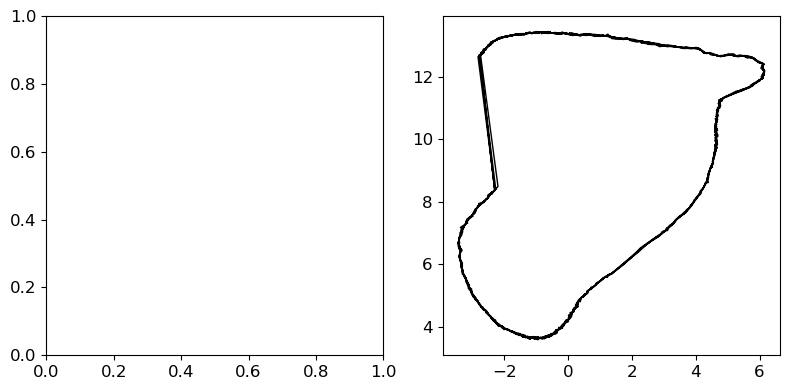

In [103]:
# tmp_l = int(len(tmp_emb))
fig, axes = plt.subplots(1, 2, figsize=size, gridspec_kw={'width_ratios': [1, 1]})
axes[1].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='black', lw=1)
# axes[1].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, linestyle = 'dashed', label='Soft')

In [115]:
size = (8,4)
xmin = -10
xmax = 15
ymin = 0
ymax = 18
wid = 1

norm = plt.Normalize(ode_min, ode_max)
cm = plt.cm.viridis
sm = plt.cm.ScalarMappable(cmap=cm, norm=norm)

x_lin = np.arange(0,1,0.001)

C:\Users\olesk\AppData\Local\Temp\ipykernel_15276\2842361761.py:104: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.savefig(fig4a_fn, bbox_inches='tight')


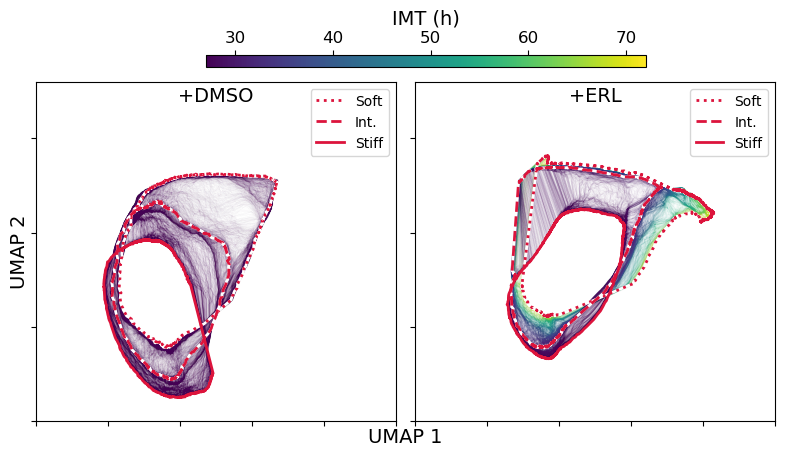

In [118]:
fig, axes = plt.subplots(1, 2, figsize=size, gridspec_kw={'width_ratios': [1, 1]})

params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

ii=0
for f in filenames_dmso:
    tmp_emb = np.genfromtxt(f, delimiter=',')

    axes[0].plot(tmp_emb[:,0], tmp_emb[:,1], color=cm(norm(ode_divs_dmso[ii])), lw=0.01, alpha=0.5)
    ii+=1
    
ii=0
for f in filenames_erl:
    tmp_emb = np.genfromtxt(f, delimiter=',')

    axes[1].plot(tmp_emb[:,0], tmp_emb[:,1], color=cm(norm(ode_divs_erl[ii])), lw=0.01, alpha=0.5)
    ii+=1
    
# ind = np.where(embedding_index == 112) 
# x=np.ndarray.tolist(embedding_tmp[ind,0])
# y=np.ndarray.tolist(embedding_tmp[ind,1])
# axes[1].plot(x[0][int(len(x[0])/2):], y[0][int(len(x[0])/2):], color='cyan', lw=1)
# ind = np.where(embedding_index == 113) 
# x=np.ndarray.tolist(embedding_tmp[ind,0])
# y=np.ndarray.tolist(embedding_tmp[ind,1])
# axes[1].plot(x[0][int(len(x[0])/2):], y[0][int(len(x[0])/2):], color='magenta', lw=1)
    
    
lw = 2

tmp_emb = np.genfromtxt(filenames_erl[0], delimiter=',')
tmp_l = int(len(tmp_emb)/4)
# tmp_l = int(len(tmp_emb))
axes[1].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='white', lw=lw)
axes[1].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, linestyle = 'dotted', label='Soft')
tmp_emb = np.genfromtxt(filenames_erl[499], delimiter=',')
tmp_l = 600
axes[1].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='white', lw=lw)
axes[1].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, linestyle = 'dashed', label='Int.')
tmp_emb = np.genfromtxt(filenames_erl[999], delimiter=',') 
tmp_l = int(len(tmp_emb)/4)
axes[1].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, label='Stiff')
plt.legend(loc=1)

plt.rcParams['axes.titley'] = 1
plt.rcParams['axes.titlepad'] = -14
axes[1].set_xlim([xmin, xmax])
axes[1].set_ylim([ymin, ymax])
axes[1].title.set_text('+ERL')
axes[1].axes.yaxis.set_ticks([0, 5, 10, 15])
axes[1].axes.yaxis.set_ticklabels([])
    
# ii=0
# for num in range(1001,2001):
#     ind = np.where(embedding_index == num) 
#     x=np.ndarray.tolist(embedding_tmp[ind,0])
#     y=np.ndarray.tolist(embedding_tmp[ind,1])
#     axes[0].plot(x[0], y[0], color=cm(norm(ode_divs_dmso[ii])), lw=0.05)
#     ii+=1

tmp_emb = np.genfromtxt(filenames_dmso[0], delimiter=',')
tmp_l = int(len(tmp_emb)/4)
axes[0].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='white', lw=lw)
axes[0].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, linestyle = 'dotted', label='Soft')
tmp_emb = np.genfromtxt(filenames_dmso[499], delimiter=',')
tmp_l = 430
axes[0].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='white', lw=lw)
axes[0].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, linestyle = 'dashed', label='Int.')
tmp_emb = np.genfromtxt(filenames_dmso[999], delimiter=',') 
tmp_l = int(len(tmp_emb)/4)
axes[0].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, label='Stiff')
axes[0].legend(loc=1)    

axes[0].set_xlim([xmin, xmax])
axes[0].set_ylim([ymin, ymax])
axes[0].title.set_text('+DMSO')
axes[0].axes.yaxis.set_ticks([0, 5, 10, 15])

axes[0].set_yticklabels([])
axes[0].set_xticklabels([])
axes[1].set_yticklabels([])
axes[1].set_xticklabels([])

fig.subplots_adjust(top=1)
cbar_ax = fig.add_axes([0.27, 1, 0.55, 0.03])
fig.colorbar(sm, cax=cbar_ax, orientation='horizontal', location='top', label='IMT (h)')

ax = fig.add_subplot(111, frameon=False)
ax.set_xticks([])
ax.set_yticks([])
#plt.tick_params(labelcolor='none', top='off', bottom='off', left='off', right='off')
ax.set_xlabel('UMAP 1', labelpad=5)
ax.set_ylabel('UMAP 2', labelpad=5)

fig4a_fn = Path(SAVEDIR, 'fig4a.svg')

if SAVEFILES and (OVERWRITE or not fig4a_fn.exists()):
    plt.savefig(fig4a_fn, bbox_inches='tight')
else:
    plt.figure()


In [119]:
norm = plt.Normalize(-0.04, 0)
cm = plt.cm.cividis
sm = plt.cm.ScalarMappable(cmap=cm, norm=norm)

In [120]:
filenames_dmso_100 = filenames_dmso[0::10]
filenames_erl_100 = filenames_erl[0::10]

In [121]:
len(filenames_erl_100)

100

C:\Users\olesk\AppData\Local\Temp\ipykernel_15276\433253171.py:116: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.savefig(fig4a_fn, bbox_inches='tight')


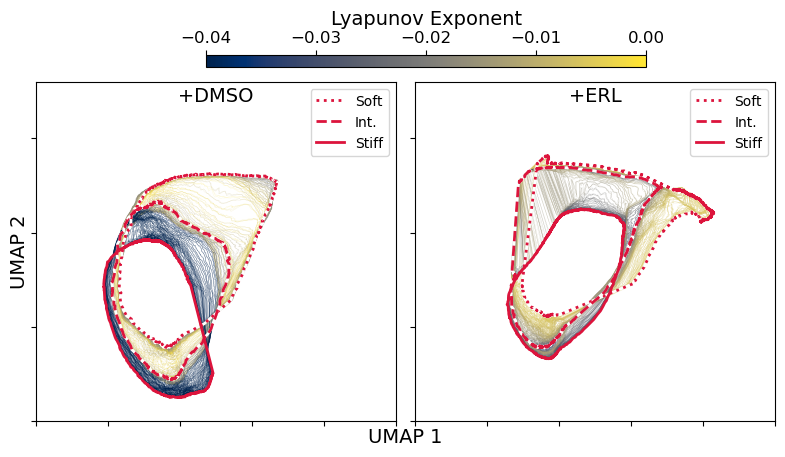

In [123]:
fig, axes = plt.subplots(1, 2, figsize=size, gridspec_kw={'width_ratios': [1, 1]})

params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

ii=0
for f in filenames_dmso_100:
    tmp_emb = np.genfromtxt(f, delimiter=',')

    axes[0].plot(tmp_emb[:,0], tmp_emb[:,1], color=cm(norm(lyap_dmso[ii])), lw=0.1, alpha=0.5)
    ii+=1
    
ii=0
for f in filenames_erl_100:
    tmp_emb = np.genfromtxt(f, delimiter=',')

    axes[1].plot(tmp_emb[:,0], tmp_emb[:,1], color=cm(norm(lyap_erl[ii])), lw=0.1, alpha=0.5)
    ii+=1
    
# ind = np.where(embedding_index == 112) 
# x=np.ndarray.tolist(embedding_tmp[ind,0])
# y=np.ndarray.tolist(embedding_tmp[ind,1])
# axes[1].plot(x[0][int(len(x[0])/2):], y[0][int(len(x[0])/2):], color='cyan', lw=1)
# ind = np.where(embedding_index == 113) 
# x=np.ndarray.tolist(embedding_tmp[ind,0])
# y=np.ndarray.tolist(embedding_tmp[ind,1])
# axes[1].plot(x[0][int(len(x[0])/2):], y[0][int(len(x[0])/2):], color='magenta', lw=1)
    
lw = 2

tmp_emb = np.genfromtxt(filenames_erl[0], delimiter=',')
tmp_l = int(len(tmp_emb)/4)
axes[1].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='white', lw=lw)
axes[1].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, linestyle = 'dotted', label='Soft')
tmp_emb = np.genfromtxt(filenames_erl[499], delimiter=',')
tmp_l = 600
axes[1].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='white', lw=lw)
axes[1].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, linestyle = 'dashed', label='Int.')
tmp_emb = np.genfromtxt(filenames_erl[999], delimiter=',') 
tmp_l = int(len(tmp_emb)/4)
axes[1].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, label='Stiff')
plt.legend(loc=1)

plt.rcParams['axes.titley'] = 1
plt.rcParams['axes.titlepad'] = -14
axes[1].set_xlim([xmin, xmax])
axes[1].set_ylim([ymin, ymax])
axes[1].title.set_text('+ERL')
axes[1].axes.yaxis.set_ticks([0, 5, 10, 15])
axes[1].axes.yaxis.set_ticklabels([])
    
# ii=0
# for num in range(1001,2001):
#     ind = np.where(embedding_index == num) 
#     x=np.ndarray.tolist(embedding_tmp[ind,0])
#     y=np.ndarray.tolist(embedding_tmp[ind,1])
#     axes[0].plot(x[0], y[0], color=cm(norm(ode_divs_dmso[ii])), lw=0.05)
#     ii+=1

tmp_emb = np.genfromtxt(filenames_dmso[0], delimiter=',')
tmp_l = int(len(tmp_emb)/4)
axes[0].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='white', lw=lw)
axes[0].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, linestyle = 'dotted', label='Soft')
tmp_emb = np.genfromtxt(filenames_dmso[499], delimiter=',')
tmp_l = 430
axes[0].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='white', lw=lw)
axes[0].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, linestyle = 'dashed', label='Int.')
tmp_emb = np.genfromtxt(filenames_dmso[999], delimiter=',') 
tmp_l = int(len(tmp_emb)/4)
axes[0].plot(tmp_emb[:tmp_l,0], tmp_emb[:tmp_l,1], color='crimson', lw=lw, label='Stiff')
axes[0].legend(loc=1)     
# ind = np.where(embedding_index == 1001) 
# x=np.ndarray.tolist(embedding_tmp[ind,0])
# y=np.ndarray.tolist(embedding_tmp[ind,1])
# axes[0].plot(x[0][int(len(x[0])/2):], y[0][int(len(x[0])/2):], color='dodgerblue', lw=1, linestyle = 'dotted', label='Soft')
# ind = np.where(embedding_index == 1500) 
# x=np.ndarray.tolist(embedding_tmp[ind,0])
# y=np.ndarray.tolist(embedding_tmp[ind,1])
# axes[0].plot(x[0][int(len(x[0])/2):], y[0][int(len(x[0])/2):], color='dodgerblue', lw=1, linestyle = 'dashed', label='Int.')
# ind = np.where(embedding_index == 2000) 
# x=np.ndarray.tolist(embedding_tmp[ind,0])
# y=np.ndarray.tolist(embedding_tmp[ind,1])
# axes[0].plot(x[0][int(len(x[0])/2):], y[0][int(len(x[0])/2):], color='dodgerblue', lw=1, label='Stiff')
# axes[0].legend(loc=1)

axes[0].set_xlim([xmin, xmax])
axes[0].set_ylim([ymin, ymax])
axes[0].title.set_text('+DMSO')
axes[0].axes.yaxis.set_ticks([0, 5, 10, 15])

axes[0].set_yticklabels([])
axes[0].set_xticklabels([])
axes[1].set_yticklabels([])
axes[1].set_xticklabels([])

fig.subplots_adjust(top=1)
cbar_ax = fig.add_axes([0.27, 1, 0.55, 0.03])
fig.colorbar(sm, cax=cbar_ax, ticks=[-0.04, -0.03, -0.02, -0.01, 0], 
             orientation='horizontal', location='top', label='Lyapunov Exponent')

ax = fig.add_subplot(111, frameon=False)
ax.set_xticks([])
ax.set_yticks([])
#plt.tick_params(labelcolor='none', top='off', bottom='off', left='off', right='off')
ax.set_xlabel('UMAP 1', labelpad=5)
ax.set_ylabel('UMAP 2', labelpad=5)

fig4a_fn = Path(SAVEDIR, 'fig4a_lyap.svg')

if SAVEFILES and (OVERWRITE or not fig4a_fn.exists()):
    plt.savefig(fig4a_fn, bbox_inches='tight')
else:
    plt.figure()


In [40]:
ode_divs_erl[0]

array([-1.507514, 14.6665  ])

In [107]:
params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 24,
         'axes.titlesize': 24,
         'axes.edgecolor': "black",
         'xtick.labelsize': 20,
         'ytick.labelsize': 20}
plt.rcParams.update(params)

(-0.1, 0.02)

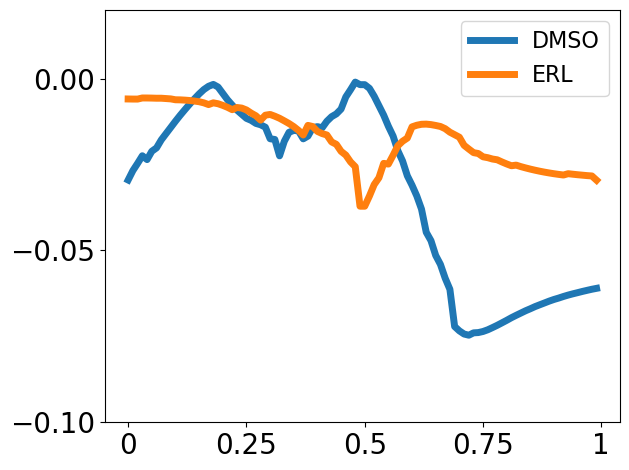

In [119]:
plt.plot(lyap_dmso, label="DMSO", lw=5)
plt.plot(lyap_erl, label='ERL', lw=5)
plt.legend(fontsize=16)
locs, labels = plt.xticks() 
plt.xticks([0, 25, 50, 75, 100], [0, 0.25, 0.5, 0.75, 1])
plt.yticks([-0.1, -0.05, 0])

plt.ylim(-0.1, 0.02)

In [26]:
np.argmin(lyap_dmso)


72

In [61]:
size = (2,2)
xmin = 0
xmax = 14
ymin = -2
ymax = 16
wid = 1

norm = plt.Normalize(ode_min, ode_max)
cm = plt.cm.viridis
sm = plt.cm.ScalarMappable(cmap=cm, norm=norm)

x_lin = np.arange(0,1,0.001)

In [62]:
filenames_dmso_100 = filenames_dmso[0::10]
filenames_erl_100 = filenames_erl[0::10]

In [96]:
params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 30,
         'axes.titlesize': 30,
         'xtick.labelsize': 30,
         'ytick.labelsize': 30}
plt.rcParams.update(params)

[Text(1, 0, '30'), Text(1, 1, '75')]

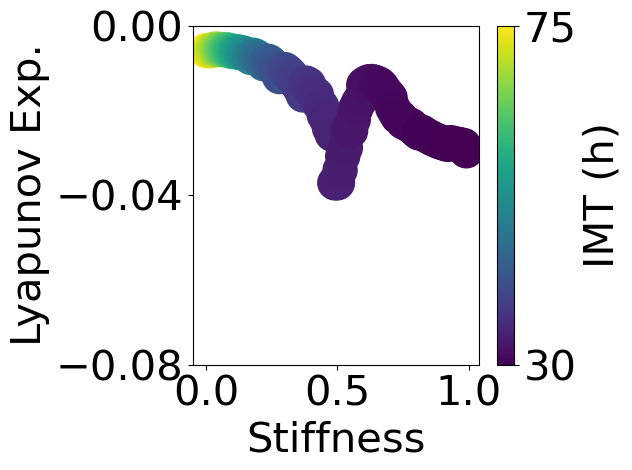

In [98]:
fig = plt.figure()


sca = plt.scatter(x_lin[0::10], lyap_erl, color=cm(norm(ode_divs_erl[0::10])), s=600)
# plt.xlim([0, 1])
plt.ylim([-0.08, 0])
plt.xticks([0, 0.5, 1])
plt.yticks([-0.08, -0.04, 0])

plt.xlabel('Stiffness')
plt.ylabel('Lyapunov Exp.')

cbar = fig.colorbar(sca, ticks=[0, 1], label='IMT (h)')
cbar.ax.set_yticklabels(['30', '75']) 

# plt.colorbar(label='IMT')


[Text(1, 0, '30'), Text(1, 1, '75')]

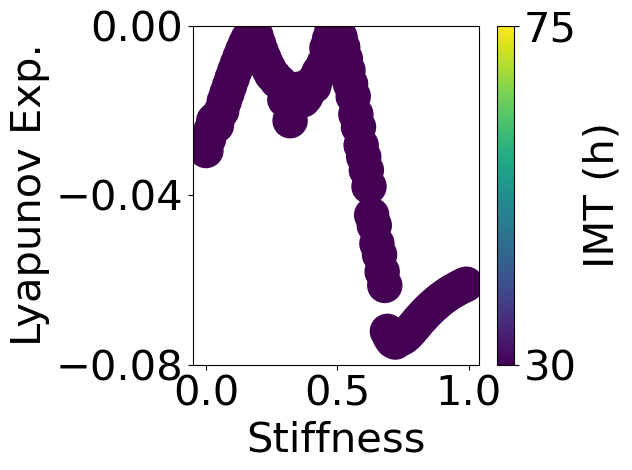

In [104]:
fig = plt.figure()


sca = plt.scatter(x_lin[0::10], lyap_dmso, color=cm(norm(ode_divs_dmso[0::10])), s=600)
# plt.xlim([0, 1])
plt.ylim([-0.08, 0])
plt.xticks([0, 0.5, 1])
plt.yticks([-0.08, -0.04, 0])

plt.xlabel('Stiffness')
plt.ylabel('Lyapunov Exp.')

cbar = fig.colorbar(sca, ticks=[0, 1], label='IMT (h)')
cbar.ax.set_yticklabels(['30', '75']) 




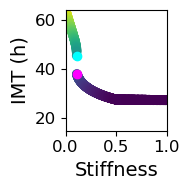

In [65]:
fig = plt.figure(figsize=size)

params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

plt.scatter(x_lin, ode_divs_erl, color=cm(norm(ode_divs_erl)))
plt.scatter(x_lin[111], ode_divs_erl[111], color='cyan')
plt.scatter(x_lin[112], ode_divs_erl[112], color='magenta')
plt.xlim([0, 1])
plt.ylim([15, ode_max])
plt.xlabel('Stiffness')
plt.ylabel('IMT (h)')

fig4a_fn = Path(SAVEDIR, 'fig4a_inset02.svg')

if SAVEFILES and (OVERWRITE or not fig4a_fn.exists()):
    plt.savefig(fig4a_fn, bbox_inches='tight')
else:
    plt.figure()

In [68]:
ode_divs_erl[112]

38.0

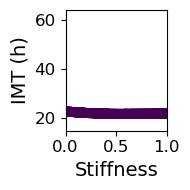

In [66]:
fig = plt.figure(figsize=size)

params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.titlesize': 14,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

plt.scatter(x_lin, ode_divs_dmso, color=cm(norm(ode_divs_dmso)))
plt.xlim([0, 1])
plt.ylim([15, ode_max])
plt.xlabel('Stiffness')
plt.ylabel('IMT (h)')

fig4a_fn = Path(SAVEDIR, 'fig4a_inset55.svg')

if SAVEFILES and (OVERWRITE or not fig4a_fn.exists()):
    plt.savefig(fig4a_fn, bbox_inches='tight')
else:
    plt.figure()

In [20]:
lyap_erl = pd.read_csv(Path(DATADIR+'/lyap_avg_0402.txt'),header=None)
lyap_dmso = pd.read_csv(Path(DATADIR+'/lyap_avg_dmso.txt'),header=None)
lyap_sum = pd.read_csv(Path(DATADIR+'/lyap_sum.txt'),header=None)
x_lin = np.arange(0,1,0.01)

,0,1,2,3,4,5,6,7,8,9,...,90,91,92,93,94,95,96,97,98,99
0,-0.04136,-0.048568,-0.0459,-0.042825,-0.050461,-0.05301,-0.056804,-0.063553,-0.058667,-0.047035,...,-0.046495,-0.046783,-0.046434,-0.045941,-0.04638,-0.047972,-0.047182,-0.04611,-0.051876,-0.047787


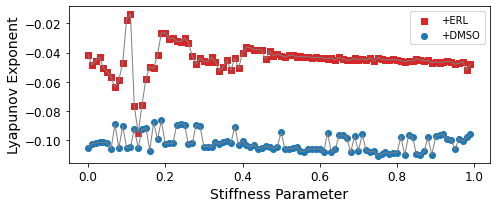

In [26]:
win = 21
pol = 2
size = (7,3)
xmin = 0
xmax = 1
ymin = -.12
ymax = 0

fig = plt.figure(figsize=size)

params = {'axes.titley': 1,
         'axes.titlepad': -14,
         'axes.labelsize': 14,
         'axes.edgecolor': "black",
         'axes.titlesize': 14,
         'xtick.labelsize': 12,
         'ytick.labelsize': 12}
plt.rcParams.update(params)

norm = plt.Normalize(min(lyap_dmso.iloc[0,:]), max(lyap_erl.iloc[0,:]))
cm = plt.cm.viridis
sm = plt.cm.ScalarMappable(cmap=cm, norm=norm)

plt.scatter(x_lin, lyap_erl.iloc[0,:], color='tab:red', label='+ERL', marker='s')
plt.plot(x_lin, lyap_erl.iloc[0,:], color='gray', linewidth=1)
plt.scatter(x_lin, lyap_dmso.iloc[0,:], color='tab:blue', label='+DMSO')
plt.plot(x_lin, lyap_dmso.iloc[0,:], color='gray', linewidth=1)
plt.xlabel('Stiffness Parameter')
plt.ylabel('Lyapunov Exponent')
plt.legend()

fig4b = Path(SAVEDIR, 'fig4b.svg')

if SAVEFILES and (OVERWRITE or not fig4b.exists()):
    plt.savefig(fig4b, bbox_inches='tight')
else:
    plt.figure()